# Momentum: empirical loss curves versus the bootstrap theorem

This notebook integrates the exact phase-covariance closure for the matrix-valued quadratic loss

$$\ell(S_{vu})=\frac12\lVert S_{vu}-S_{\mathrm{teach}}\rVert_F^2,\qquad S_{\mathrm{teach}}\in\mathbb R^{d_v\times d_u}.$$

The default teacher is a normalized rectangular identity with $\lVert S_{\mathrm{teach}}\rVert_F^2=2$. This recovers $S_{\mathrm{teach}}=\sqrt2$ and $\Delta_0=1$ when $d_u=d_v=1$, while allowing unequal dimensions.

For each of three two-scale white initialization scales, it compares the empirical loss gap with the literal rigorous bound $3\overline{\mathcal E}_0e^{-\lambda_s(\gamma)t}$. Each dotted curve uses a strictly admissible deformation budget just inside the first bootstrap boundary.


In [1]:
from __future__ import annotations

import os
from dataclasses import dataclass
from pathlib import Path

os.environ.setdefault("MPLCONFIGDIR", "/tmp/matplotlib")

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D
from numpy.typing import NDArray
from scipy.integrate import solve_ivp
from scipy.optimize import brentq

Array = NDArray[np.float64]

D_U = 3
D_V = 2
if D_U < 1 or D_V < 1:
    raise ValueError("D_U and D_V must be positive")
M = D_U + D_V
KAPPA = 1.0
SMOOTHNESS_L = 1.0
SIGMA_PQ = 1.0
TEACHER_RANK = min(D_U, D_V)
TEACHER_VU = np.sqrt(2.0 / TEACHER_RANK) * np.eye(D_V, D_U)
DELTA_0 = 0.5 * float(np.sum(TEACHER_VU**2))
EBAR_0 = DELTA_0 + 0.5 * M * SIGMA_PQ**2
SIGMA_VU_VALUES = np.asarray([200.0, 500.0, 1000.0])
GAMMA_VALUES = np.asarray([30.0, 100.0, 300.0, 1000.0])
T_FINAL = 10.0
LOSS_DISPLAY_FLOOR = 1e-14
ETA_GRID = 1.0 / (1.0 + np.exp(-np.linspace(-14.0, 14.0, 40001)))

# Locate the repository from any directory beneath it.
cwd = Path.cwd()
ROOT = next((p for p in (cwd, *cwd.parents) if (p / "code" / "figures").is_dir()), None)
if ROOT is None:
    raise RuntimeError("Run this notebook from inside the repository")
FIGURE_DIR = ROOT / "code" / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_STEM = FIGURE_DIR / "momentum_empirical_vs_theory_by_sigma"

plt.rcParams.update({
    "font.size": 7,
    "font.family": "serif",
    "axes.titlesize": 9,
    "axes.labelsize": 8,
    "legend.fontsize": 7,
    "figure.dpi": 140,
    "savefig.dpi": 300,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

gamma_colors = dict(zip(GAMMA_VALUES, plt.get_cmap("magma")(np.linspace(0.15, 0.85, len(GAMMA_VALUES)))))


## Bootstrap certificate

The first zero crossing of $\mathfrak S_s(\gamma)-s$ is refined with Brent's method. We then move into the negative-gap interval, so the plotted exponent is supplied by a deformation budget satisfying the theorem's strict inequality rather than by the non-admissible boundary itself.


In [2]:
@dataclass(frozen=True)
class Certificate:
    sigma_vu: float
    gamma: float
    boundary_s: float
    admissible_s: float
    gap: float
    rate: float


def certificate_quantities(s: Array | float, sigma_vu: float, gamma: float) -> tuple[Array, Array]:
    s_array = np.asarray(s, dtype=float)
    a_s = sigma_vu**2 * np.exp(-2.0 * s_array)
    b_s = sigma_vu**2 * np.exp(2.0 * s_array)
    rho_s = 4.0 * b_s * SMOOTHNESS_L + 2.0 * np.sqrt(2.0 * SMOOTHNESS_L * EBAR_0)
    rate = a_s * KAPPA * gamma / (rho_s + 2.0 * gamma**2)
    deformation_bound = (4.0 / rate) * np.sqrt(3.0 * EBAR_0 / (2.0 * a_s))
    return deformation_bound - s_array, rate


def strict_certificate(sigma_vu: float, gamma: float) -> Certificate:
    s_grid = np.unique(np.concatenate([
        np.geomspace(1e-10, 5.0, 8000),
        np.linspace(1e-4, 1.5, 5000),
    ]))
    gaps, _ = certificate_quantities(s_grid, sigma_vu, gamma)
    crossings = np.flatnonzero((gaps[:-1] >= 0.0) & (gaps[1:] < 0.0))
    if len(crossings) == 0:
        raise RuntimeError(f"No first admissible bootstrap boundary for sigma_vu={sigma_vu:g}, gamma={gamma:g}")

    index = int(crossings[0])
    lower = float(s_grid[index])
    upper = float(s_grid[index + 1])
    boundary_s = brentq(
        lambda value: float(certificate_quantities(value, sigma_vu, gamma)[0]),
        lower,
        upper,
        xtol=1e-14,
        rtol=1e-13,
    )
    # The midpoint between the boundary and a verified negative-gap grid point
    # is strictly admissible while staying close to the sharp boundary rate.
    admissible_s = 0.5 * (boundary_s + upper)
    gap, rate = certificate_quantities(admissible_s, sigma_vu, gamma)
    gap_value = float(gap)
    rate_value = float(rate)
    if not gap_value < 0.0:
        raise RuntimeError("Interior bootstrap budget is not strictly admissible")
    return Certificate(sigma_vu, gamma, boundary_s, admissible_s, gap_value, rate_value)


certificates = {
    (float(sigma_vu), float(gamma)): strict_certificate(float(sigma_vu), float(gamma))
    for sigma_vu in SIGMA_VU_VALUES
    for gamma in GAMMA_VALUES
}

print(f"Constructed {len(certificates)} strict bootstrap certificates.")


Constructed 12 strict bootstrap certificates.


## Exact phase-covariance solves

With phase ordering $(u,v,p,q)$, the covariance satisfies $\dot\Sigma=M\Sigma+\Sigma M^\top$, where $M=\left(\begin{smallmatrix}0&I\\-G&-\gamma I\end{smallmatrix}\right)$ and $G=\left(\begin{smallmatrix}0&E^\top\\E&0\end{smallmatrix}\right)$ for $E=S_{vu}-S_{\mathrm{teach}}\in\mathbb R^{d_v\times d_u}$. The full covariance system avoids inverses and does not impose the reduced CSI relations numerically.


In [3]:
@dataclass(frozen=True)
class MomentumResult:
    sigma_vu: float
    gamma: float
    t: Array
    covariance: Array
    loss: Array
    mechanical_energy: Array
    min_eigenvalue: float
    max_eigenvalue: float
    max_symmetry_error: float
    nfev: int


def predictor_vu(position_covariance: Array) -> Array:
    return position_covariance[..., D_U:M, :D_U]


def predictor_loss(predictor: Array) -> Array:
    residual = predictor - TEACHER_VU
    return 0.5 * np.sum(residual**2, axis=(-2, -1))


def predictor_gradient(predictor: Array) -> Array:
    return predictor - TEACHER_VU


def phase_force(gradient_vu: Array) -> Array:
    if gradient_vu.shape != (D_V, D_U):
        raise ValueError(f"Expected a {(D_V, D_U)} predictor gradient, got {gradient_vu.shape}")
    return np.block([
        [np.zeros((D_U, D_U)), gradient_vu.T],
        [gradient_vu, np.zeros((D_V, D_V))],
    ])


def phase_covariance_rhs(_t: float, flat_sigma: Array, gamma: float) -> Array:
    sigma = flat_sigma.reshape(2 * M, 2 * M)
    sigma = 0.5 * (sigma + sigma.T)
    predictor = predictor_vu(sigma[:M, :M])
    force = phase_force(predictor_gradient(predictor))
    generator = np.block([
        [np.zeros((M, M)), np.eye(M)],
        [-force, -gamma * np.eye(M)],
    ])
    return (generator @ sigma + sigma @ generator.T).reshape(-1)


def evaluation_times() -> Array:
    # Resolve the scale-dependent transient near zero without oversampling the tail.
    return np.unique(np.concatenate([
        np.asarray([0.0]),
        np.geomspace(1e-8, 1e-1, 1200),
        np.linspace(1e-1, T_FINAL, 3001),
    ]))


def solve_momentum_covariance(sigma_vu: float, gamma: float) -> MomentumResult:
    position0 = sigma_vu**2 * np.eye(M)
    velocity0 = SIGMA_PQ**2 * np.eye(M)
    covariance0 = np.block([
        [position0, np.zeros((M, M))],
        [np.zeros((M, M)), velocity0],
    ])
    t_eval = evaluation_times()
    solution = solve_ivp(
        phase_covariance_rhs,
        (0.0, T_FINAL),
        covariance0.reshape(-1),
        args=(gamma,),
        method="DOP853",
        t_eval=t_eval,
        rtol=2e-9,
        atol=1e-11,
    )
    if not solution.success:
        raise RuntimeError(f"ODE solve failed for sigma_vu={sigma_vu:g}, gamma={gamma:g}: {solution.message}")

    raw_path = solution.y.T.reshape(-1, 2 * M, 2 * M)
    symmetry_errors = np.linalg.norm(raw_path - raw_path.transpose(0, 2, 1), axis=(1, 2))
    covariance_path = 0.5 * (raw_path + raw_path.transpose(0, 2, 1))
    predictor = predictor_vu(covariance_path[:, :M, :M])
    loss = predictor_loss(predictor)
    kinetic = 0.5 * np.trace(covariance_path[:, M:, M:], axis1=1, axis2=2)
    mechanical_energy = loss + kinetic
    eigenvalues = np.linalg.eigvalsh(covariance_path)

    return MomentumResult(
        sigma_vu=sigma_vu,
        gamma=gamma,
        t=solution.t,
        covariance=covariance_path,
        loss=loss,
        mechanical_energy=mechanical_energy,
        min_eigenvalue=float(np.min(eigenvalues)),
        max_eigenvalue=float(np.max(eigenvalues)),
        max_symmetry_error=float(np.max(symmetry_errors)),
        nfev=int(solution.nfev),
    )


results = {}
for sigma_vu in SIGMA_VU_VALUES:
    for gamma in GAMMA_VALUES:
        key = (float(sigma_vu), float(gamma))
        results[key] = solve_momentum_covariance(*key)
    print(f"Finished sigma_vu={sigma_vu:g}")


Finished sigma_vu=200
Finished sigma_vu=500
Finished sigma_vu=1000


## Numerical verification


In [4]:
verification_rows = []
for key, result in results.items():
    certificate = certificates[key]
    theory_bound = 3.0 * EBAR_0 * np.exp(-certificate.rate * result.t)
    energy_increase = float(np.max(np.diff(result.mechanical_energy)))
    energy_tolerance = 2e-7 * max(1.0, float(result.mechanical_energy[0]))
    psd_tolerance = 2e-8 * max(1.0, result.max_eigenvalue)
    bound_violation = float(np.max(result.loss - theory_bound))
    bound_tolerance = 2e-7 * max(1.0, float(theory_bound[0]))

    assert certificate.gap < 0.0
    assert result.max_symmetry_error <= 1e-10 * max(1.0, result.max_eigenvalue)
    assert result.min_eigenvalue >= -psd_tolerance
    assert energy_increase <= energy_tolerance
    assert bound_violation <= bound_tolerance

    verification_rows.append({
        "sigma_vu": result.sigma_vu,
        "gamma": result.gamma,
        "s": certificate.admissible_s,
        "gap": certificate.gap,
        "rate": certificate.rate,
        "final_loss": float(result.loss[-1]),
        "min_eigenvalue": result.min_eigenvalue,
        "max_energy_increase": energy_increase,
        "max_bound_violation": bound_violation,
        "nfev": result.nfev,
    })

print(f"All {len(verification_rows)} solves passed certificate, symmetry, PSD, energy, and theorem-bound checks.")
print("rate range:", min(row["rate"] for row in verification_rows), "to", max(row["rate"] for row in verification_rows))
print("total RHS evaluations:", sum(row["nfev"] for row in verification_rows))


All 12 solves passed certificate, symmetry, PSD, energy, and theorem-bound checks.
rate range: 7.23027450405686 to 166.63595321383787
total RHS evaluations: 489477


## Initialization-scale panels

Solid curves are empirical covariance-ODE losses. Dotted curves are the literal rigorous theorem bounds, with matching colors denoting the same damping value in every panel.


In [ ]:
fig, axes_grid = plt.subplots(2, 3, figsize=(9.0, 5.3), sharex=True, sharey=True, constrained_layout=True)
axes = list(axes_grid.flat[:len(SIGMA_VU_VALUES)])
for unused_axis in axes_grid.flat[len(SIGMA_VU_VALUES):]:
    fig.delaxes(unused_axis)

for ax, sigma_vu in zip(axes, SIGMA_VU_VALUES):
    for gamma in GAMMA_VALUES:
        key = (float(sigma_vu), float(gamma))
        result = results[key]
        certificate = certificates[key]
        color = gamma_colors[gamma]
        empirical_display = np.maximum(result.loss, LOSS_DISPLAY_FLOOR)
        theory_bound = 3.0 * EBAR_0 * np.exp(-certificate.rate * result.t)
        ax.plot(result.t, empirical_display, color=color, linewidth=1.15, alpha=0.95)
        ax.plot(result.t, theory_bound, color=color, linewidth=1.25, linestyle=":")

    ax.set_title(rf"$\sigma_{{vu}}={sigma_vu:g}$")
    ax.set_yscale("log")
    ax.set_xlim(0.0, T_FINAL)
    ax.set_ylim(LOSS_DISPLAY_FLOOR, 10.0)
    ax.grid(True, which="both", color="#E8E8E8", linewidth=0.65)
    ax.set_xlabel(r"time $t$")

for ax in axes[::3]:
    ax.set_ylabel(r"loss gap $\ell(S_{vu,t})-\ell_\star$")

gamma_handles = [
    Line2D([0], [0], color=gamma_colors[gamma], linewidth=1.8, label=rf"$\gamma={gamma:g}$")
    for gamma in GAMMA_VALUES
]
style_handles = [
    Line2D([0], [0], color="#555555", linewidth=1.5, linestyle="-", label="empirical"),
    Line2D([0], [0], color="#555555", linewidth=1.5, linestyle=":", label="rigorous bound"),
]
fig.legend(handles=gamma_handles, loc="upper center", bbox_to_anchor=(0.835, 0.40), ncol=1, frameon=False)
fig.legend(handles=style_handles, loc="lower center", bbox_to_anchor=(0.835, 0.10), frameon=False)
fig.suptitle("Momentum covariance flow: empirical loss versus bootstrap theorem")

for suffix in ("pdf", "png", "pgf"):
    fig.savefig(FIGURE_STEM.with_suffix(f".{suffix}"), bbox_inches="tight")

print("Saved:", ", ".join(str(FIGURE_STEM.with_suffix(f".{suffix}")) for suffix in ("pdf", "png", "pgf")))
plt.show()


## Empirical envelope and observed-spectrum conditional rates

We now separate the two sources of conservatism. The empirical envelope rate is fitted to the logarithms of the local loss maxima after the initial 20% of peaks; when a trajectory has fewer than three resolved peaks, its monotone log-linear tail is fitted instead. The a posteriori conditional rate uses the actual extrema

$$a_{\rm emp}=\inf_t\lambda_{\min}(\Sigma_t^{xx}),\qquad b_{\rm emp}=\sup_t\lambda_{\max}(\Sigma_t^{xx})$$

in Proposition 7.10. This is a diagnostic rather than an a priori certificate, because it uses the computed trajectory.


In [5]:
from scipy.signal import find_peaks


@dataclass(frozen=True)
class RateDiagnostic:
    sigma_vu: float
    gamma: float
    bootstrap_rate: float
    conditional_empirical_spectrum_rate: float
    eta_approx_rate: float
    eta_approx: float
    epsilon_approx: float
    q_approx: float
    eta_grid_rate: float
    eta_grid: float
    epsilon_grid: float
    q_grid: float
    empirical_envelope_rate: float
    empirical_envelope_prefactor: float
    envelope_fit_r_squared: float
    envelope_fit_method: str
    envelope_fit_count: int
    envelope_fit_t_start: float
    envelope_fit_t_end: float
    a_empirical: float
    b_empirical: float
    empirical_distortion_budget: float
    certificate_budget: float


def conditional_rate_from_spectrum(a: float, b: float, gamma: float) -> float:
    if not (0.0 < a <= b):
        raise ValueError(f"Expected 0 < a <= b, got a={a}, b={b}")
    rho = 4.0 * b * SMOOTHNESS_L + 2.0 * np.sqrt(2.0 * SMOOTHNESS_L * EBAR_0)
    return a * KAPPA * gamma / (rho + 2.0 * gamma**2)


def dimension_sharpened_rho(mathfrak_l: float) -> float:
    """Hessian coefficient from the dimension-free phase-covariance bound."""
    return mathfrak_l + 2.0 * np.sqrt(2.0 * SMOOTHNESS_L * EBAR_0)


def eta_approx_rate_from_spectrum(
    a: float, b: float, gamma: float
) -> tuple[float, float, float, float]:
    """Evaluate the dimension-sharpened rate at the explicit eta approximation."""
    if not (0.0 < a <= b):
        raise ValueError(f"Expected 0 < a <= b, got a={a}, b={b}")
    mathfrak_k = 4.0 * a * KAPPA
    mathfrak_l = 4.0 * b * SMOOTHNESS_L
    rho = dimension_sharpened_rho(mathfrak_l)
    eta_approx = gamma / (gamma + np.sqrt(gamma**2 + 2.0 * rho))
    A_approx = (1.0 - eta_approx) * mathfrak_k
    B_approx = rho + gamma**2 / (2.0 * eta_approx)
    epsilon_approx = 2.0 * gamma / (A_approx + B_approx)
    q_approx = epsilon_approx * np.sqrt(mathfrak_l / 2.0)
    if not q_approx < 1.0:
        raise RuntimeError("Explicit eta approximation violates Lyapunov equivalence")
    lambda_approx = epsilon_approx * A_approx / (1.0 + q_approx)
    return float(lambda_approx), float(eta_approx), float(epsilon_approx), float(q_approx)


def eta_grid_rate_from_spectrum(
    a: float, b: float, gamma: float
) -> tuple[float, float, float, float]:
    """Maximize the dimension-sharpened rate over the configured eta grid."""
    if not (0.0 < a <= b):
        raise ValueError(f"Expected 0 < a <= b, got a={a}, b={b}")
    mathfrak_k = 4.0 * a * KAPPA
    mathfrak_l = 4.0 * b * SMOOTHNESS_L
    rho = dimension_sharpened_rho(mathfrak_l)
    A_grid = (1.0 - ETA_GRID) * mathfrak_k
    B_grid = rho + gamma**2 / (2.0 * ETA_GRID)
    epsilon_grid = 2.0 * gamma / (A_grid + B_grid)
    q_grid = epsilon_grid * np.sqrt(mathfrak_l / 2.0)
    lambda_grid = epsilon_grid * A_grid / (1.0 + q_grid)
    best_index = int(np.argmax(lambda_grid))
    if not q_grid[best_index] < 1.0:
        raise RuntimeError("Grid-optimized correction violates Lyapunov equivalence")
    return (
        float(lambda_grid[best_index]),
        float(ETA_GRID[best_index]),
        float(epsilon_grid[best_index]),
        float(q_grid[best_index]),
    )


def fit_empirical_envelope(result: MomentumResult) -> tuple[float, float, float, str, Array]:
    peak_indices, _ = find_peaks(result.loss)
    peak_indices = peak_indices[result.loss[peak_indices] > 1e-12]

    if len(peak_indices) >= 3:
        # Remove the earliest nonlinear transient when enough peaks are available.
        start = int(0.2 * len(peak_indices)) if len(peak_indices) >= 8 else 0
        fit_indices = peak_indices[start:]
        method = "local maxima"
    else:
        # With no resolved rebounds, the loss is its own upper envelope. Fit a
        # tail window safely above the floating-point loss floor.
        fit_indices = np.flatnonzero((result.loss <= 1e-3) & (result.loss >= 1e-11))
        if len(fit_indices) > 200:
            fit_indices = fit_indices[int(0.2 * len(fit_indices)):]
        method = "monotone tail"

    if len(fit_indices) < 3:
        raise RuntimeError(
            f"Insufficient envelope samples for sigma_vu={result.sigma_vu:g}, gamma={result.gamma:g}"
        )
    fit_t = result.t[fit_indices]
    fit_log_loss = np.log(result.loss[fit_indices])
    slope, intercept = np.polyfit(fit_t, fit_log_loss, deg=1)
    fitted = slope * fit_t + intercept
    residual_sum = float(np.sum((fit_log_loss - fitted)**2))
    total_sum = float(np.sum((fit_log_loss - np.mean(fit_log_loss))**2))
    r_squared = 1.0 - residual_sum / total_sum
    rate = -float(slope)
    if not rate > 0.0:
        raise RuntimeError("Empirical envelope fit did not decay")
    return rate, float(np.exp(intercept)), r_squared, method, fit_indices


rate_diagnostics = {}
envelope_fit_indices = {}
for key, result in results.items():
    position_path = result.covariance[:, :M, :M]
    position_eigenvalues = np.linalg.eigvalsh(position_path)
    a_empirical = float(np.min(position_eigenvalues))
    b_empirical = float(np.max(position_eigenvalues))
    initial_position_eigenvalue = result.sigma_vu**2
    empirical_distortion_budget = max(
        0.5 * np.log(b_empirical / initial_position_eigenvalue),
        0.5 * np.log(initial_position_eigenvalue / a_empirical),
    )
    envelope_rate, envelope_prefactor, fit_r_squared, fit_method, fit_indices = fit_empirical_envelope(result)
    lambda_approx, eta_approx, epsilon_approx, q_approx = eta_approx_rate_from_spectrum(
        a_empirical, b_empirical, result.gamma
    )
    lambda_grid, eta_grid, epsilon_grid, q_grid = eta_grid_rate_from_spectrum(
        a_empirical, b_empirical, result.gamma
    )
    certificate = certificates[key]
    diagnostic = RateDiagnostic(
        sigma_vu=result.sigma_vu,
        gamma=result.gamma,
        bootstrap_rate=certificate.rate,
        conditional_empirical_spectrum_rate=conditional_rate_from_spectrum(
            a_empirical, b_empirical, result.gamma
        ),
        eta_approx_rate=lambda_approx,
        eta_approx=eta_approx,
        epsilon_approx=epsilon_approx,
        q_approx=q_approx,
        eta_grid_rate=lambda_grid,
        eta_grid=eta_grid,
        epsilon_grid=epsilon_grid,
        q_grid=q_grid,
        empirical_envelope_rate=envelope_rate,
        empirical_envelope_prefactor=envelope_prefactor,
        envelope_fit_r_squared=fit_r_squared,
        envelope_fit_method=fit_method,
        envelope_fit_count=len(fit_indices),
        envelope_fit_t_start=float(result.t[fit_indices[0]]),
        envelope_fit_t_end=float(result.t[fit_indices[-1]]),
        a_empirical=a_empirical,
        b_empirical=b_empirical,
        empirical_distortion_budget=float(empirical_distortion_budget),
        certificate_budget=certificate.admissible_s,
    )
    assert diagnostic.envelope_fit_r_squared >= 0.99
    assert diagnostic.empirical_distortion_budget <= diagnostic.certificate_budget + 1e-8
    rate_diagnostics[key] = diagnostic
    envelope_fit_indices[key] = fit_indices

conditional_over_bootstrap = np.asarray([
    value.conditional_empirical_spectrum_rate / value.bootstrap_rate
    for value in rate_diagnostics.values()
])
empirical_over_conditional = np.asarray([
    value.empirical_envelope_rate / value.conditional_empirical_spectrum_rate
    for value in rate_diagnostics.values()
])
empirical_over_eta_approx = np.asarray([
    value.empirical_envelope_rate / value.eta_approx_rate
    for value in rate_diagnostics.values()
])
empirical_over_eta_grid = np.asarray([
    value.empirical_envelope_rate / value.eta_grid_rate
    for value in rate_diagnostics.values()
])
eta_grid_over_eta_approx = np.asarray([
    value.eta_grid_rate / value.eta_approx_rate
    for value in rate_diagnostics.values()
])
distortion_fraction = np.asarray([
    value.empirical_distortion_budget / value.certificate_budget
    for value in rate_diagnostics.values()
])

print(f"Computed {len(rate_diagnostics)} rate diagnostics; all envelope fits have R^2 >= 0.99.")
print("conditional / bootstrap rate: median", float(np.median(conditional_over_bootstrap)),
      "range", (float(np.min(conditional_over_bootstrap)), float(np.max(conditional_over_bootstrap))))
print("empirical envelope / conditional rate: median", float(np.median(empirical_over_conditional)),
      "range", (float(np.min(empirical_over_conditional)), float(np.max(empirical_over_conditional))))
print("empirical envelope / dimension-sharp eta_approx rate: median", float(np.median(empirical_over_eta_approx)),
      "range", (float(np.min(empirical_over_eta_approx)), float(np.max(empirical_over_eta_approx))))
print("empirical envelope / dimension-sharp eta-grid rate: median", float(np.median(empirical_over_eta_grid)),
      "range", (float(np.min(empirical_over_eta_grid)), float(np.max(empirical_over_eta_grid))))
print("eta-grid / explicit eta_approx rate: median", float(np.median(eta_grid_over_eta_approx)),
      "range", (float(np.min(eta_grid_over_eta_approx)), float(np.max(eta_grid_over_eta_approx))))
print("observed / certified distortion budget: median", float(np.median(distortion_fraction)),
      "range", (float(np.min(distortion_fraction)), float(np.max(distortion_fraction))))


Computed 12 rate diagnostics; all envelope fits have R^2 >= 0.99.
conditional / bootstrap rate: median 1.0033856019410194 range (1.0001812572187816, 1.0256374568783537)
empirical envelope / conditional rate: median 4.35044835059206 range (3.997815887518672, 12.050231608043353)
empirical envelope / dimension-sharp eta_approx rate: median 1.3297201424046818 range (1.0204192023843928, 3.4959488353368617)
empirical envelope / dimension-sharp eta-grid rate: median 1.32832238673209 range (1.0204186128516166, 3.4285012564429134)
eta-grid / explicit eta_approx rate: median 1.0010147864461207 range (1.0000005777362042, 1.0219022556138848)
observed / certified distortion budget: median 0.005855955353943127 range (0.0007992811914837756, 0.011858331347631512)


In [ ]:
RATE_FIGURE_STEM = FIGURE_DIR / "momentum_rate_diagnostics_by_sigma"
fig_rate, rate_axes_grid = plt.subplots(2, 3, figsize=(9.0, 5.3), sharex=True, sharey=True, constrained_layout=True)
rate_axes = list(rate_axes_grid.flat[:len(SIGMA_VU_VALUES)])
for unused_axis in rate_axes_grid.flat[len(SIGMA_VU_VALUES):]:
    fig_rate.delaxes(unused_axis)

rate_styles = {
    "bootstrap": dict(color="#D55E00", marker="o", linestyle=":", label="bootstrap certificate"),
    "conditional": dict(color="#0072B2", marker="s", linestyle="--", label="conditional (observed spectrum)"),
    "eta_approx": dict(color="#CC79A7", marker="x", linestyle="--", label=r"dimension-sharp $\eta_{\rm approx}$"),
    "eta_grid": dict(color="#009E73", marker="^", linestyle="-.", label=r"dimension-sharp grid $\eta$"),
    "empirical": dict(color="#222222", marker="D", linestyle="-", label="empirical envelope"),
}

for ax, sigma_vu in zip(rate_axes, SIGMA_VU_VALUES):
    diagnostics = [rate_diagnostics[(float(sigma_vu), float(gamma))] for gamma in GAMMA_VALUES]
    ax.plot(GAMMA_VALUES, [value.bootstrap_rate for value in diagnostics], linewidth=1.4, markersize=4.0, **rate_styles["bootstrap"])
    ax.plot(GAMMA_VALUES, [value.conditional_empirical_spectrum_rate for value in diagnostics], linewidth=1.4, markersize=4.0, **rate_styles["conditional"])
    ax.plot(GAMMA_VALUES, [value.eta_approx_rate for value in diagnostics], linewidth=1.4, markersize=4.5, **rate_styles["eta_approx"])
    ax.plot(GAMMA_VALUES, [value.eta_grid_rate for value in diagnostics], linewidth=1.4, markersize=4.0, **rate_styles["eta_grid"])
    ax.plot(GAMMA_VALUES, [value.empirical_envelope_rate for value in diagnostics], linewidth=1.5, markersize=4.0, **rate_styles["empirical"])
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_title(rf"$\sigma_{{vu}}={sigma_vu:g}$")
    ax.set_xlabel(r"damping $\gamma$")
    ax.grid(True, which="both", color="#E8E8E8", linewidth=0.65)

for ax in rate_axes[::3]:
    ax.set_ylabel(r"loss exponent $\lambda$")
rate_legend_handles = [
    Line2D([0], [0], linewidth=1.5, markersize=4.0, **style)
    for style in rate_styles.values()
]
fig_rate.legend(handles=rate_legend_handles, loc="center", bbox_to_anchor=(0.835, 0.27), frameon=False)
fig_rate.suptitle("Momentum loss rates: locating the conservatism")

for suffix in ("pdf", "png", "pgf"):
    fig_rate.savefig(RATE_FIGURE_STEM.with_suffix(f".{suffix}"), bbox_inches="tight")

print("Saved:", ", ".join(str(RATE_FIGURE_STEM.with_suffix(f".{suffix}")) for suffix in ("pdf", "png", "pgf")))
plt.show()


## Figure 4: loss trajectories versus the tightened conditional bound

Tube selection uses the paper's current dimension-free bootstrap criterion,

$$\rho_s=4b_sL+2\sqrt{2L\overline{\mathcal E}_0},\qquad
\lambda_s(\gamma)=\frac{a_s\kappa\gamma}{\rho_s+2\gamma^2},\qquad
\mathfrak S_s(\gamma)=\frac{4}{\lambda_s(\gamma)}\sqrt{\frac{3\overline{\mathcal E}_0}{2a_s}}<s.$$

For each initialization scale and damping value, `strict_certificate` selects a budget just inside the first feasible boundary. On that certified tube, the dotted curves use the tightened conditional rate at the explicit $\eta_{\mathrm{approx}}$. The grid-optimized rate is also computed as a diagnostic but is not plotted. Because the two-scale white initialization has zero initial predictor velocity, its corrected Lyapunov functional starts at $\mathcal V_0=\overline{\mathcal E}_0$. For either selected value of $\eta$, the global mechanical-energy bound (and hence predictor-loss bound) is

$$\overline{\mathcal E}_t\leq \frac{\overline{\mathcal E}_0}{1-q_{\eta}}e^{-\lambda_{\eta}t}.$$


Maximum empirical-minus-eta_approx-bound value: 8.391e-17
Maximum empirical-minus-eta-grid-bound value: 8.391e-17
Saved: /Users/stephen.zhang/Projects/linear-networks-global/python/figures/momentum_empirical_vs_tightened_theory_by_sigma.pdf, /Users/stephen.zhang/Projects/linear-networks-global/python/figures/momentum_empirical_vs_tightened_theory_by_sigma.png, /Users/stephen.zhang/Projects/linear-networks-global/python/figures/momentum_empirical_vs_tightened_theory_by_sigma.pgf


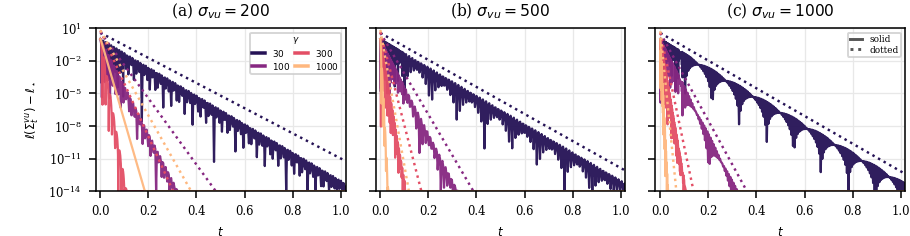

In [6]:
PLOT_T_FINAL = 1.0
TIGHTENED_FIGURE_STEM = FIGURE_DIR / "momentum_empirical_vs_tightened_theory_by_sigma"
fig_eta_approx, eta_approx_axes_grid = plt.subplots(
    1, 3, figsize=(6.5, 1.6875), sharex=True, sharey=True, constrained_layout=False
)
fig_eta_approx.subplots_adjust(left=0.105, right=0.995, bottom=0.19, top=0.88, wspace=0.12)
eta_approx_axes = list(eta_approx_axes_grid.flat)
max_eta_approx_bound_violation = -np.inf
max_eta_grid_bound_violation = -np.inf
eta_approx_bootstrap_tube_parameters = {}
eta_grid_bootstrap_tube_parameters = {}

for panel_index, (ax, sigma_vu) in enumerate(zip(eta_approx_axes, SIGMA_VU_VALUES)):
    for gamma in GAMMA_VALUES:
        key = (float(sigma_vu), float(gamma))
        result = results[key]
        certificate = certificates[key]
        certified_a = sigma_vu**2 * np.exp(-2.0 * certificate.admissible_s)
        certified_b = sigma_vu**2 * np.exp(2.0 * certificate.admissible_s)
        lambda_approx, eta_approx, epsilon_approx, q_approx = eta_approx_rate_from_spectrum(
            certified_a, certified_b, gamma
        )
        lambda_grid, eta_grid, epsilon_grid, q_grid = eta_grid_rate_from_spectrum(
            certified_a, certified_b, gamma
        )
        eta_approx_bootstrap_tube_parameters[key] = (
            lambda_approx, eta_approx, epsilon_approx, q_approx
        )
        eta_grid_bootstrap_tube_parameters[key] = (
            lambda_grid, eta_grid, epsilon_grid, q_grid
        )
        assert certificate.gap < 0.0
        color = gamma_colors[gamma]
        empirical_display = np.maximum(result.loss, LOSS_DISPLAY_FLOOR)
        eta_approx_bound = (
            EBAR_0
            / (1.0 - q_approx)
            * np.exp(-lambda_approx * result.t)
        )
        eta_grid_bound = (
            EBAR_0
            / (1.0 - q_grid)
            * np.exp(-lambda_grid * result.t)
        )
        max_eta_approx_bound_violation = max(
            max_eta_approx_bound_violation, float(np.max(result.loss - eta_approx_bound))
        )
        max_eta_grid_bound_violation = max(
            max_eta_grid_bound_violation, float(np.max(result.loss - eta_grid_bound))
        )
        ax.plot(result.t, empirical_display, color=color, linewidth=1.15, alpha=0.95)
        ax.plot(result.t, eta_approx_bound, color=color, linewidth=1.25, linestyle=":")
        # ax.plot(result.t, eta_grid_bound, color=color, linewidth=1.25, linestyle="-.")

    panel_label = "abc"[panel_index]
    ax.set_title(rf"({panel_label}) $\sigma_{{vu}}={sigma_vu:g}$", fontsize=8)
    ax.set_yscale("log")
    ax.set_xlim(-0.02 * PLOT_T_FINAL, 1.02 * PLOT_T_FINAL)
    ax.set_ylim(LOSS_DISPLAY_FLOOR, 10.0)
    ax.grid(True, which="both", color="#E8E8E8", linewidth=0.65)
    ax.set_xlabel(r"$t$", fontsize=6)
    ax.tick_params(axis="both", labelsize=6)

for ax in eta_approx_axes[::3]:
    ax.set_ylabel(r"$\ell(\Sigma^{vu}_t)-\ell_\star$", fontsize=6)
eta_approx_gamma_handles = [
    Line2D([0], [0], color=gamma_colors[gamma], linewidth=1.8, label=rf"${gamma:g}$")
    for gamma in GAMMA_VALUES
]
eta_approx_style_handles = [
    Line2D([0], [0], color="#555555", linewidth=1.5, linestyle="-", label="solid"),
    Line2D([0], [0], color="#555555", linewidth=1.5, linestyle=":", label=r"dotted"),
#    Line2D([0], [0], color="#555555", linewidth=1.5, linestyle="-.", label=r"dimension-sharp theory (grid $\eta$)"),
]
eta_approx_axes[0].legend(
    handles=eta_approx_gamma_handles, title=r"$\gamma$", title_fontsize=4.6,
    loc="upper right", ncol=2, fontsize=4.6,
    frameon=True, borderpad=0.25, labelspacing=0.2, columnspacing=0.55, handlelength=1.4
)
eta_approx_axes[2].legend(
    handles=eta_approx_style_handles, loc="upper right", ncol=1, fontsize=4.6,
    frameon=True, borderpad=0.25, labelspacing=0.2, handlelength=1.4
)

bound_tolerance = 2e-7 * max(1.0, EBAR_0)
assert max_eta_approx_bound_violation <= bound_tolerance
assert max_eta_grid_bound_violation <= bound_tolerance

for suffix in ("pdf", "png", "pgf"):
    fig_eta_approx.savefig(TIGHTENED_FIGURE_STEM.with_suffix(f".{suffix}"))

print(f"Maximum empirical-minus-eta_approx-bound value: {max_eta_approx_bound_violation:.3e}")
print(f"Maximum empirical-minus-eta-grid-bound value: {max_eta_grid_bound_violation:.3e}")
print("Saved:", ", ".join(str(TIGHTENED_FIGURE_STEM.with_suffix(f".{suffix}")) for suffix in ("pdf", "png", "pgf")))
plt.show()
